

Loading the data using pandas


In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("googleplaystore.csv")
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [2]:
df.shape

(10841, 13)

Checking for null values and getting the number if null values in each column


In [3]:
df.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Dropping records with nulls in any of the columns

In [4]:
df = df.dropna()
df.isnull().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

In [5]:
#resetting the index
df = df.reset_index(drop=True)

Fixing Formatting and data types

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9360 entries, 0 to 9359
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             9360 non-null   object 
 1   Category        9360 non-null   object 
 2   Rating          9360 non-null   float64
 3   Reviews         9360 non-null   object 
 4   Size            9360 non-null   object 
 5   Installs        9360 non-null   object 
 6   Type            9360 non-null   object 
 7   Price           9360 non-null   object 
 8   Content Rating  9360 non-null   object 
 9   Genres          9360 non-null   object 
 10  Last Updated    9360 non-null   object 
 11  Current Ver     9360 non-null   object 
 12  Android Ver     9360 non-null   object 
dtypes: float64(1), object(12)
memory usage: 950.8+ KB


Fixing the size column

In [7]:
#displaying every unique value in the size column
print(df['Size'].unique())

['19M' '14M' '8.7M' '25M' '2.8M' '5.6M' '29M' '33M' '3.1M' '28M' '12M'
 '20M' '21M' '37M' '5.5M' '17M' '39M' '31M' '4.2M' '23M' '6.0M' '6.1M'
 '4.6M' '9.2M' '5.2M' '11M' '24M' 'Varies with device' '9.4M' '15M' '10M'
 '1.2M' '26M' '8.0M' '7.9M' '56M' '57M' '35M' '54M' '201k' '3.6M' '5.7M'
 '8.6M' '2.4M' '27M' '2.7M' '2.5M' '7.0M' '16M' '3.4M' '8.9M' '3.9M'
 '2.9M' '38M' '32M' '5.4M' '18M' '1.1M' '2.2M' '4.5M' '9.8M' '52M' '9.0M'
 '6.7M' '30M' '2.6M' '7.1M' '22M' '6.4M' '3.2M' '8.2M' '4.9M' '9.5M'
 '5.0M' '5.9M' '13M' '73M' '6.8M' '3.5M' '4.0M' '2.3M' '2.1M' '42M' '9.1M'
 '55M' '23k' '7.3M' '6.5M' '1.5M' '7.5M' '51M' '41M' '48M' '8.5M' '46M'
 '8.3M' '4.3M' '4.7M' '3.3M' '40M' '7.8M' '8.8M' '6.6M' '5.1M' '61M' '66M'
 '79k' '8.4M' '3.7M' '118k' '44M' '695k' '1.6M' '6.2M' '53M' '1.4M' '3.0M'
 '7.2M' '5.8M' '3.8M' '9.6M' '45M' '63M' '49M' '77M' '4.4M' '70M' '9.3M'
 '8.1M' '36M' '6.9M' '7.4M' '84M' '97M' '2.0M' '1.9M' '1.8M' '5.3M' '47M'
 '556k' '526k' '76M' '7.6M' '59M' '9.7M' '78M' '72M' '4

In [8]:
#Cleaning the Size Column
def clean_size(x):
    if x == 'Varies with device':
        return np.nan
    elif 'M' in x:
        return float(x.replace('M', '')) * 1000
    elif 'k' in x:
        return float(x.replace('k', ''))
    return np.nan


In [9]:
df['Size'] = df['Size'].apply(clean_size)

In [10]:
print(df['Size'].unique())

[1.90e+04 1.40e+04 8.70e+03 2.50e+04 2.80e+03 5.60e+03 2.90e+04 3.30e+04
 3.10e+03 2.80e+04 1.20e+04 2.00e+04 2.10e+04 3.70e+04 5.50e+03 1.70e+04
 3.90e+04 3.10e+04 4.20e+03 2.30e+04 6.00e+03 6.10e+03 4.60e+03 9.20e+03
 5.20e+03 1.10e+04 2.40e+04      nan 9.40e+03 1.50e+04 1.00e+04 1.20e+03
 2.60e+04 8.00e+03 7.90e+03 5.60e+04 5.70e+04 3.50e+04 5.40e+04 2.01e+02
 3.60e+03 5.70e+03 8.60e+03 2.40e+03 2.70e+04 2.70e+03 2.50e+03 7.00e+03
 1.60e+04 3.40e+03 8.90e+03 3.90e+03 2.90e+03 3.80e+04 3.20e+04 5.40e+03
 1.80e+04 1.10e+03 2.20e+03 4.50e+03 9.80e+03 5.20e+04 9.00e+03 6.70e+03
 3.00e+04 2.60e+03 7.10e+03 2.20e+04 6.40e+03 3.20e+03 8.20e+03 4.90e+03
 9.50e+03 5.00e+03 5.90e+03 1.30e+04 7.30e+04 6.80e+03 3.50e+03 4.00e+03
 2.30e+03 2.10e+03 4.20e+04 9.10e+03 5.50e+04 2.30e+01 7.30e+03 6.50e+03
 1.50e+03 7.50e+03 5.10e+04 4.10e+04 4.80e+04 8.50e+03 4.60e+04 8.30e+03
 4.30e+03 4.70e+03 3.30e+03 4.00e+04 7.80e+03 8.80e+03 6.60e+03 5.10e+03
 6.10e+04 6.60e+04 7.90e+01 8.40e+03 3.70e+03 1.18e

Replacing Nans with median

In [11]:
df['Size'] = df['Size'].fillna(df['Size'].median())

In [12]:
print(df['Size'].isna().sum())

0


In [13]:
#Checking if size is numeric
df['Size'].dtype

dtype('float64')

In [14]:
#Converting Reviews to numeric
df['Reviews'] = df['Reviews'].astype(float)


In [15]:
df['Reviews'].dtype

dtype('float64')

Fixing Installs

In [16]:
#Replacing '+', ',' and converting to integer
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(int)

In [17]:
print(df['Installs'].head())
print(df['Installs'].dtype)

0       10000
1      500000
2     5000000
3    50000000
4      100000
Name: Installs, dtype: int64
int64


Fixing Price

In [18]:
#removing '$' and converting to numeric
df['Price'] = df['Price'].str.replace('$', '', regex=False).astype(float)

In [19]:
print(df['Price'].head())
print(df['Price'].dtype)

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Price, dtype: float64
float64


In [20]:
df.dtypes

App                object
Category           object
Rating            float64
Reviews           float64
Size              float64
Installs            int64
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

Sanity Checks

In [21]:
#Rating should be between 1 and 5, dropping rows outside the range
df = df.drop(df[df['Rating'] > 5].index)
df = df.drop(df[df['Rating'] < 1].index)

In [22]:
#Reviews should not be greater than installs, only review if installed
df = df[df['Reviews'] <= df['Installs']]

In [23]:
#for type=free, price should be 0
df = df.drop(df[(df['Type'] == 'Free') & (df['Price'] > 0)].index)

In [24]:
df = df.reset_index(drop=True)

Univariate analysis

<AxesSubplot: xlabel='Price'>

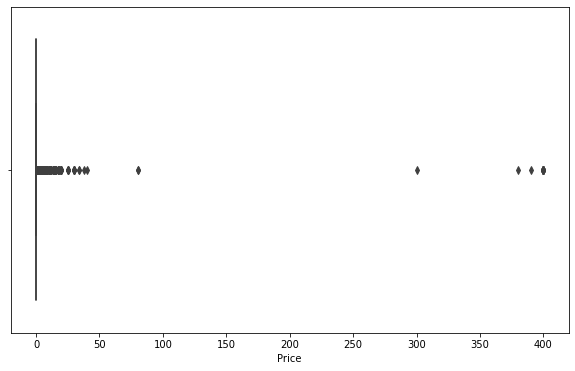

In [25]:
#box plot for price
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Price'])

Most apps are priced at or near 0, with the median also being close to zero.However, there are significant outliers with prices reaching up to $400, suggesting a small number of unusually expensive apps that may be junk or incorrectly priced

<AxesSubplot: xlabel='Reviews'>

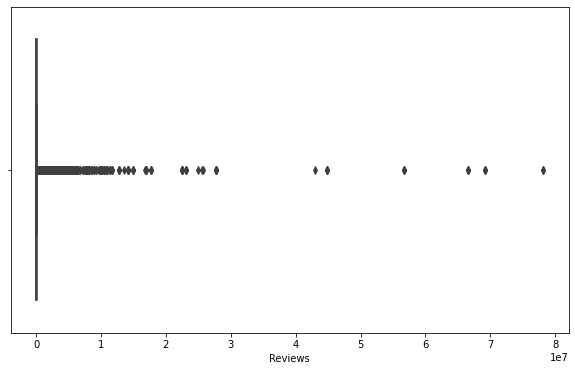

In [26]:
_#Reviews Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Reviews'])

Most apps have reviews clustered very close to 0. Outliers are scattered between approximately 10 million and 40 million, with the most extreme outlier sitting at around 40 million reviews.

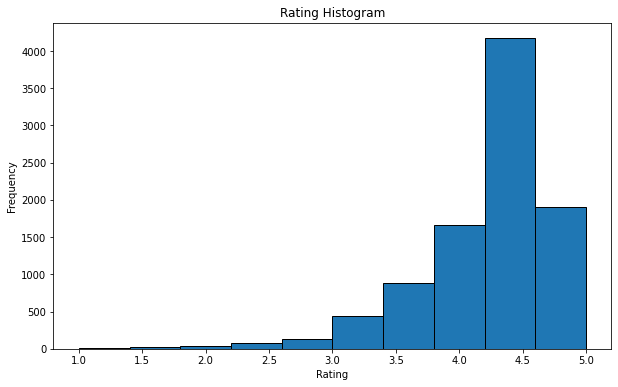

In [27]:
#Rating Histogram
plt.figure(figsize=(10, 6))
plt.hist(df['Rating'], bins=10, edgecolor='black')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.title('Rating Histogram')
plt.show()

Ratings are heavily concentrated between 4.0 and 5.0, suggesting users generally rate apps positively on the Play Store. Very few apps receive low ratings.

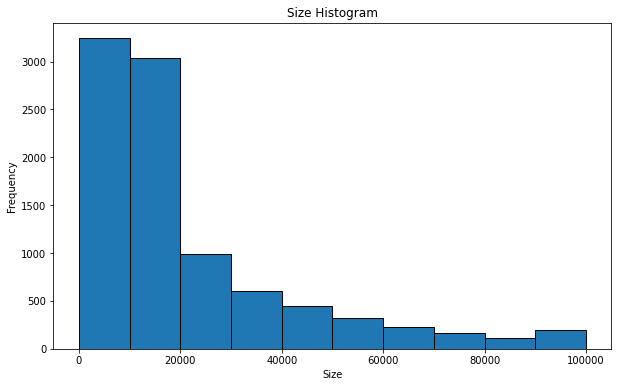

In [28]:
#Size Histogram
plt.figure(figsize=(10, 6))
plt.hist(df['Size'], bins=10, edgecolor='black')
plt.xlabel('Size')
plt.ylabel('Frequency')
plt.title('Size Histogram')
plt.show()


The distribution is right-skewed, with the majority of apps falling within the 0 to 20,000 KB range. Frequency steadily decreases as size increases, indicating that most apps on the Play Store are relatively small. Very few apps exceed 60,000 KB, suggesting that large apps are uncommon.

Outlier treatment

Checking out the records with very high prices (>'$200).

In [29]:
print("Apps priced at $200 or more:")
display(df[df['Price'] >= 200][['App', 'Price', 'Category']])

Apps priced at $200 or more:


,App,Price,Category
4035,most expensive app (H),399.99,FAMILY
4188,💎 I'm rich,399.99,LIFESTYLE
4193,I'm Rich - Trump Edition,400.00,LIFESTYLE
5040,I am rich,399.99,LIFESTYLE
5043,I am Rich Plus,399.99,FAMILY
5044,I am rich VIP,299.99,LIFESTYLE
5045,I Am Rich Premium,399.99,FINANCE
5046,I am extremely Rich,379.99,LIFESTYLE
5047,I am Rich!,399.99,FINANCE
5048,I am rich(premium),399.99,FINANCE


In [30]:
#drop prices above $200
df = df.drop(df[df['Price'] >= 200].index)

In [31]:
#Max price after dropping
print("Max price after dropping:", df['Price'].max())

Max price after dropping: 79.99


In [32]:
#Drop Apps that have more than 2 000 000 reviews
df = df.drop(df[df['Reviews'] > 2000000].index)

In [33]:
#Max reviews after dropping
print("Max reviews after dropping:", df['Reviews'].max())

Max reviews after dropping: 1986068.0


In [34]:
#Find out the different percentiles of Installs
print("Installs Percentiles:")
print(df['Installs'].quantile([0.1, 0.25, 0.5, 0.7, 0.9, 0.95, 0.99]))

Installs Percentiles:
0.10         1000.0
0.25        10000.0
0.50       500000.0
0.70      1000000.0
0.90     10000000.0
0.95     10000000.0
0.99    100000000.0
Name: Installs, dtype: float64


The 90th and 95th percentiles share the same value of 10 000 000 installs,indicating a large cluster of  Apps at 10M installs, Beyond this point, there is a siginificant jump to 100M installs at the 99th percentile, suggesting that the top 4% values are widely spread outliers, therefore the 95th percentile is selected as the uppper cut off to remove these outliers.


In [35]:
#Dropping apps that have more than 10 000 000 installs
df = df.drop(df[df['Installs'] > 10000000].index)

In [36]:
#Display Max number of installs after dropping
print("Max installs after dropping:", df['Installs'].max())


Max installs after dropping: 10000000


In [37]:
#Reset index
df = df.reset_index(drop=True)

In [38]:
print("Outlier treatment complete. Current shape of dataset:", df.shape)

Outlier treatment complete. Current shape of dataset: (8496, 13)


Bivariate Analysis : How do the available predictors relate to the traget variable

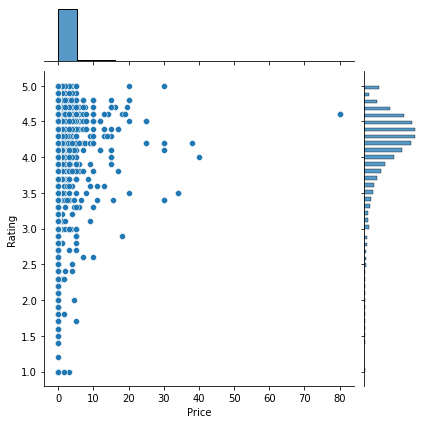

In [39]:
# Rating vs Price joinplot
sns.jointplot(y='Rating', x='Price', data=df, kind='scatter')

The majority of apps are clustered at low prices (0-'$10), with ratings spread across the full range (1-5). There is no clear pattern and rating does not increase with price. Higher priced apps do not necessarily receive better ratings.

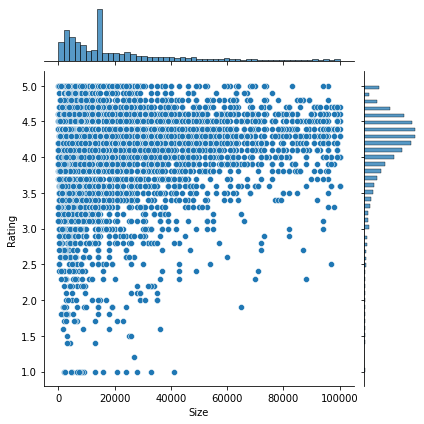

In [40]:
#size vs rating joinplot
sns.jointplot(y='Rating', x='Size', data=df, kind='scatter')


Heavier apps are not necessarily rated better. Apps are spread across the full size range (0 - 100,000 KB), with most apps regardless of size rated 3.5 and above, indicating that both light and heavy apps receive high ratings. Size does not appear to have a significant influence on rating. 

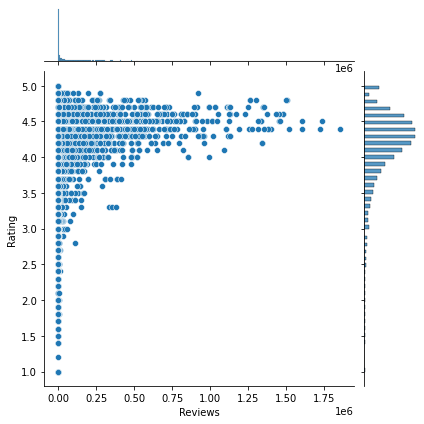

In [41]:
#Reviews vs Rating joinplot
sns.jointplot(y='Rating', x='Reviews', data=df, kind='scatter')


Rating and reviews show that more reviews do not always mean a better rating. While apps with high review counts tend to score between 4.0 and 5.0, the highest ratings are overwhelmingly clustered among apps with very few reviews, showing that high ratings are frequently achieved without high review counts.

<AxesSubplot: xlabel='Content Rating', ylabel='Rating'>

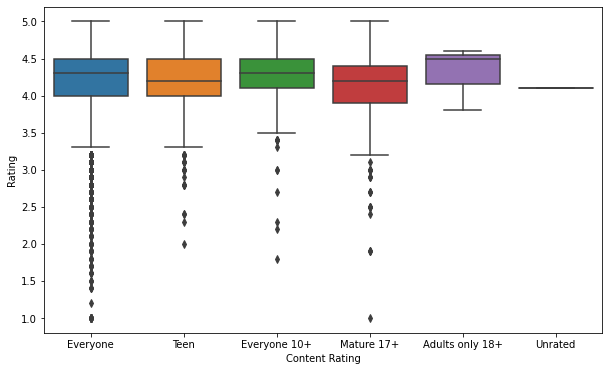

In [42]:
#Rating vs Content Rating boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='Content Rating', y='Rating', data=df)

'Adults only 18+' category appears to be liked better with the highest median score, no low outliers and no ratings lower than 4

<AxesSubplot: xlabel='Category', ylabel='Rating'>

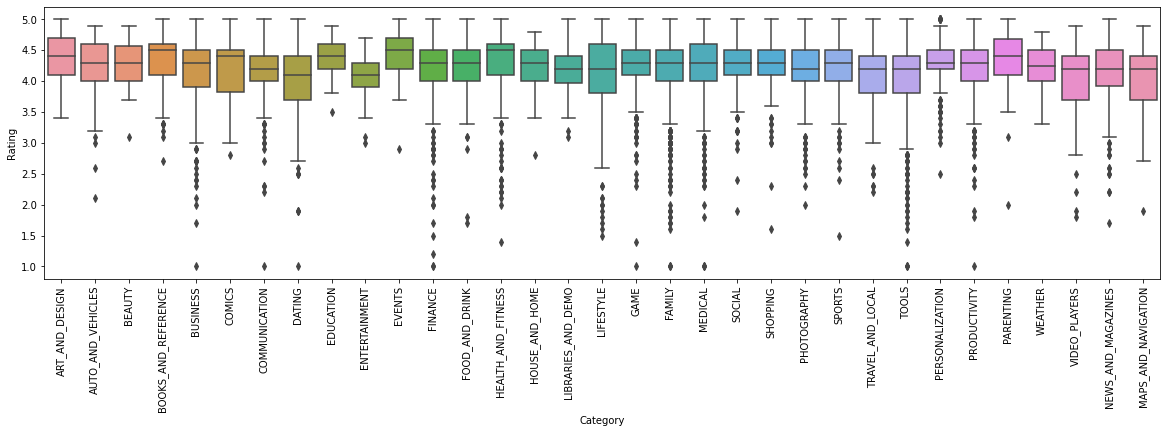

In [43]:
#Rating vs Category boxplot
plt.figure(figsize=(20, 5))
plt.xticks(rotation=90)
sns.boxplot(x='Category', y='Rating', data=df)

The Events and Health & Fitness categories appear to have the best ratings overall because their median ratings are slightly higher than those of the other categories. However, Events appears to stand out slightly, as its box is positioned at the top of the rating scale, suggesting that apps in this category are generally rated very positively.

Data Processing

In [44]:
#create a new dataframe : inp1
inp1 = df.copy()

In [45]:
#Apply log transformation to Reviews and Installs
inp1['Reviews'] = np.log1p(inp1['Reviews'])
inp1['Installs'] = np.log1p(inp1['Installs'])

In [46]:
#Dropping App, Last Updated, Current Ver  , and Android ver
inp1 = inp1.drop(['App', 'Last Updated', 'Current Ver', 'Android Ver'], axis=1)

In [47]:
inp1.head()

,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,ART_AND_DESIGN,4.1,5.075174,19000.0,9.210440,Free,0.0,Everyone,Art & Design
1,ART_AND_DESIGN,3.9,6.875232,14000.0,13.122365,Free,0.0,Everyone,Art & Design;Pretend Play
2,ART_AND_DESIGN,4.7,11.379520,8700.0,15.424949,Free,0.0,Everyone,Art & Design
3,ART_AND_DESIGN,4.3,6.875232,2800.0,11.512935,Free,0.0,Everyone,Art & Design;Creativity
4,ART_AND_DESIGN,4.4,5.123964,5600.0,10.819798,Free,0.0,Everyone,Art & Design


In [48]:
#Dummy encoding for Category,type, content rating, and genres
inp2 = pd.get_dummies(inp1, columns=['Category', 'Genres', 'Content Rating', 'Type'], drop_first=True).astype(np.int64)

In [49]:
inp2.head()

,Rating,Reviews,Size,Installs,Price,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,Category_COMICS,...,Genres_Video Players & Editors;Creativity,Genres_Video Players & Editors;Music & Video,Genres_Weather,Genres_Word,Content Rating_Everyone,Content Rating_Everyone 10+,Content Rating_Mature 17+,Content Rating_Teen,Content Rating_Unrated,Type_Paid
0,4,5,19000,9,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,3,6,14000,13,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,4,11,8700,15,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,4,6,2800,11,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,4,5,5600,10,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [50]:
#Train-test split 70-30
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(inp2, test_size=0.3, random_state=0)

print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)

Train shape: (5947, 157)
Test shape: (2549, 157)


In [51]:
#Separate into X and Y
X_train = df_train.drop('Rating', axis=1)
y_train = df_train['Rating']
X_test = df_test.drop('Rating', axis=1)
y_test = df_test['Rating']


In [52]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5947, 156)
y_train shape: (5947,)
X_test shape: (2549, 156)
y_test shape: (2549,)


Model Building

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [54]:
#R2 on the train set
y_train_pred = lr.predict(X_train)
r2_train = r2_score(y_train, y_train_pred)
print("R2 on the train set:", r2_train)

R2 on the train set: 0.10717317394606929


In [55]:
#R2 on the test set
y_test_pred = lr.predict(X_test)
r2_test = r2_score(y_test, y_test_pred)
print("R2 on the test set:", r2_test)

R2 on the test set: 0.08741956828875186
